# Линейная алгебра для машинного обучения

Линейная алгебра — это раздел математики, который изучает линейные объекты и связи между ними. Всем со школы знакомо уравнение прямой $y = ax +b$. Линейная алгебра всесторонне расширяет свойства данного объекта, причем в первую очередь под линейностью понимается обобщение свойств функции прямой пропорциональности $f(x) = ax$, для которой выполняется $a(x_1 + x_2) = ax_1 + ax_2$ (со слагаемым $b$ преобразование называется аффинным, а без $b$ — линейным).

Как ни странно, очень многое в жизни подчиняется линейной зависимости. Главной целью настоящих заметок является максимально простое введение в линейную алгебру с акцентом на ее применении в машинном обучении и современных нейросетях. Второй целью является сохранение (насколько это возможно) математической строгости.

А для тех, кто хочет соприкоснуться с НАСТОЯЩЕЙ математикой

СПИСОК ЛИТЕРАТУРЫ

1. EASY🐇: ЛЕКЦИИ. ЛИНЕЙНАЯ АЛГЕБРА И ГЕОМЕТРИЯ М. В. ЗАЙЦЕВ 

2. NORMAL👌: ЛЕКЦИИ ПО ЛИНЕЙНОЙ АЛГЕБРЕ И. М. ГЕЛЬФАНД

3. HARD😱: ЗАДАЧИ И ТЕОРЕМЫ ЛИНЕЙНОЙ АЛГЕБРЫ В. В. ПРАСОЛОВ

4. BONUS LEVEL📈: 

Применение всего математического аппарата для интерпретации машинного обучения https://geometricdeeplearning.com/book/

Учебник Яндекса по математике для ML https://contest.yandex.ru/tracks/math/

Учебник Яндекса по ML https://contest.yandex.ru/tracks/ml/

СОДЕРЖАНИЕ

1. Векторное пространство. Скалярное произведение. Линейная регрессия.

2. Матрицы, матричные произведения. Трансформеры и Attention.

3. Собственные значения.

4. Особые классы матриц. Канонический вид матриц.

5. Декомпозиция матриц и ее приложения (PCA, SVD, рекомендательные системы, LoRA и т д)

# 1. Векторное пространство. Скалярное произведение. Линейная регрессия.

## 1.1. Векторное пространство.

**Векторы и коэффициенты**

Объект, с которым мы работаем, принято называть вектором. В более суровых областях математики понимание, что это такое, может быть весьма абстрактным (**Фан факт 🔍 Вектор состояния в квантовой механике — это математический объект в гильбертовом пространстве, который содержит всю максимально возможную информацию о физическом состоянии квантовой системы**). Но для наших целей достаточно понимать его в смысле упорядоченного набора чисел. Но чтобы придать математическую строгость, нам необходимо разделить  векторы и коэффициенты (Соответственно, $x, y$ и $a, b$ в определении прямой выше)

Можно считать (канонический пример), что коэффициенты $F$ - это просто обычные действительные числа, не выходящие за рамки повседневной жизни (в них тоже, с математической точки зрения, можно навести строгость - но это нам сейчас будет только мешать), а векторы $V$ - конечный упорядоченный набор таких чисел вида $(0, 0, 0, 1,  1,  1, 0, 0, 0)$. 

*Замечание. Хотя в курсе высшей и линейной алгебры особый интерес представляет случай, когда для элементов $F$ выполнено свойство $a+a=0$, и в этом случае многие утверждения курсов линейной алгебры теряют смысл, но мы ограничимся случаем характеристики больше двух.*

Некоторые общепринятые обозначения: 

- $∀ x$ означает - для любых $x$
    
- $∃ x$ означает - найдется хотя бы один $x$
    
- двоеточие внутри математической формулы означает - "такой что"

Далее необходимый математический формализм:

НАЧАЛО ДЛИННОГО ОПРЕДЕЛЕНИЯ

$V$ - множество векторов - они должны быть **абелевой группой по сложению**, то есть определена операция сложения 
    
- 1. Коммутативная $(x + y = y + x)$ $\quad ∀ x, y$.
    
- 2. Ассоциативная $((x + y) + z = x + (y + z))$  $\quad ∀ x, y, z$.
    
- 3. В $V$ есть  нулевой элемент 0, для которого $0+x = x$  $\quad ∀ x$. 
    
- 4. Для каждого $x ∈ V$ существует противоположный элемент $−x ∈ V$, для которого $x + (−x) = 0$;

$F$ - множество коэффициентов - на них накладывается более сильное ограничение, они должны быть **полем**, то есть в дополнение к сложению $a+b$, обладающему всеми указанными выше свойствами, определена операция умножения $*$

- 5. Коммутативность умножения: $a ∗ b = b ∗ a$ $\quad ∀ a, b$.

- 6. Ассоциативность умножения:  $( a ∗ b ) ∗ c = a ∗ ( b ∗ c )$ $\quad ∀ a, b, c$.

- 7. Существование единичного элемента: $∃ 1 ∈ F ∖ { 0 }$:  $a ∗ 1 = a \quad ∀ a ∈ F$.

- 8. Существование обратного элемента для ненулевых элементов: $∀ a ∈ F : a ≠ 0$ $\quad ∃ a^{− 1} ∈ F : a ∗ a^{ − 1} = 1$.

- 9. Дистрибутивность умножения относительно сложения: $( a + b ) ∗ c = ( a ∗ c ) + ( b ∗ c ) \quad ∀ a , b , c ∈ F$.

взаимодействие этих двух множеств определяется умножением скаляров из поля $F$ на элементы $V$ (знак умножения * мы по возможности избегаем)

- 10. $a(x + y) = ax + ay$ для любых $a ∈ F, x, y ∈ V$.

- 11. $(a + b)x = ax + bx$ для любых $a, b ∈ F, x ∈ V$.
    
- 12. $(a*b)x = a(bx)$ для любых $a, b ∈ F, x ∈ V$.

- 13. $1v = v$ для любого $v ∈ V$

*Фан факт 🔍 0 и сложение в $F$ не совпадает с 0 и сложением в $V$, но чтобы не загромождать обозначения раньше времени, не будем различать эти символы.*

КОНЕЦ ДЛИННОГО ОПРЕДЕЛЕНИЯ

**Координаты и базис** 

**Def (от definition - определение):** Векторы $v_1, . . . , v_k$ из $V$ называют **линейно зависимыми**, если для некоторого набора чисел $λ_1, . . . , λ_k$ из $F$, среди которых есть число, отличное от нуля  
$$λ_1v_1 + · · · +λ_kv_k = 0.$$ 
Если $λ_i \ne 0$, то можно выразить
$$v_i = μ_1v_1 + . . .  + μ_{i−1}v_{i−1} + μ_{i+1}v_{i+1} + . . .  + μ_k v_k,$$
где $μ_j = −λ_j /λ_i$. Другими словами, векторы $v_1, . . . , v_k$ линейно зависимы тогда и только тогда, когда один из них линейно выражается через другие.


**Def:** Множество, состоящее из векторов вида $λ_1v_1 + . . . + λ_kv_k$, где $v_1, . . . , v_k$ — фиксированные векторы, а $λ_1, . . . , λ_k$ пробегают все числа из поля $F$, называют подпространством, порождённым $v_1, . . . , v_k$; мы будем
обозначать это подпространство $〈v_1, . . . , v_k〉$. Пространство, порождённое конечным набором линейно независимых векторов, называют конечномерным. 

**Def:** Набор векторов $e_1, . . . , e_n$ называют **базисом** пространства $V$, если любой вектор $v ∈ V$ единственным образом представляется в виде $v = λ_1e_1 + . . . + λ_ne_n = \sum_{j=1}^n \lambda_j e_j$. В частности, базисные векторы линейно независимы. Число $n$ называется размерностью пространства.

Если понятно, о каком базисе $e_1, e_2,...$ идет речь, то указанный выше набор чисел $(0, 0, 0, 1,  1,  1, 0, 0, 0)$ можно записать в виде $v = e_4 + e_5 + e_6$.

## 1.2. Скалярное произведение.

*Фан факт 🔍 В квантовой механике скалярное (внутреннее) произведение — это операция между двумя векторами состояния, результатом которой является комплексное число, задающее меру «близости» или перекрытия этих состояний.*

*Обозначение (нотация Дирака)*

*В квантовой механике используется бра-кет нотация:*
• *Кет-вектор $\vert{}\psi\rangle$ описывает состояние системы.*
• *Бра-вектор $\langle\phi\vert{}$ — это сопряженный линейный функционал (эрмитово-сопряженный вектор).*
• *Скалярное произведение записывается как «бра-кет» — $\langle\phi \vert{} \psi\rangle$*

Но начинать понимать скалярное произведение все-таки рекомендуется с канонического примера. Допустим, в азбуке Морзе слово NICE записывается как (1, 0, 0, 0, 1, 0, 1, 0, 0), а слово WOW записывается как (0, 1, 1, 1, 1, 1, 0, 1, 1). Естественной (для математиков) операцией между этими наборами чисел является поэлементное умножение и сложение результатов: 
$$1*0+0*1+0*1+0*1+1*1+0*1+1*0+0*1+0*1=1$$ 

Почему оно естественно? Снова вернемся в школу. **Косинус - в прямоугольном треугольнике это отношение прилежащего катета к гипотенузе.** Откуда следует, что точки на единичной окружности имеют вид  $(\cos\alpha,\sin\alpha)$.

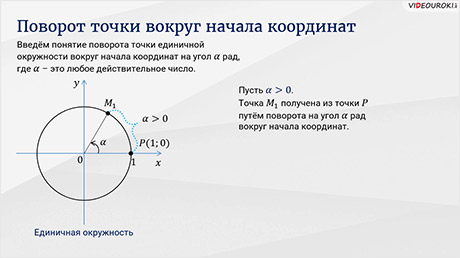

In [2]:
from IPython.display import Image
Image('IM_01.jpg', width=500, height=150 )

Если $x=(1,0)$, а $y=(\cos\alpha,\sin\alpha)$,
то скалярное произведение $x\cdot y=\cos\alpha.$
Скалярное произведение вектора единичной окружности с единичным вектором оси x — это просто косинус угла, или же проекция на ось икс.

**Определение в общем виде**

**Def:** **Скалярным произведением** векторов $x = \sum_{j=1}^n a_j e_j$ и $y = \sum_{j=1}^n b_j e_j$ в простейшем виде называется число $\sum_{j=1}^n a_j b_j$

Скалярное произведение обозначается различными способами. Например,
$$x\cdot y, \quad (x, y), \quad\langle x \vert{} y\rangle$$

 **Нормой, или длиной вектора** $|x|$ называется число $\sqrt{(x, x)}$ - корень из скалярного произведения вектора на себя (если в рассматриваемом поле $F$ операция взятия корня определена). 
 
В соответствии со школьным пониманием, косинус в общем виде определяется как: $$\cos\alpha = \frac{(x, y)}{|x||y|}.$$ Геометрически скалярное произведение - это произведение длины вектора на длину проекции второго вектора на первый (или, что то же самое, в обратном порядке). 

Значит, косинус можно рассматривать как меру близости: чем больше скалярное произведение нормированных векторов, тем более сонаправлены эти векторы. Если скалярное произведение равно нулю, то векторы называются **ортогональными** (перпендикулярными).

## 1.3. Линейная регрессия.

Линейной моделью в машинном обучении называется функция вида:
$$y=w_1x_1+…+w_Dx_D+w_0 = (x, w) + w_0,$$
- $y$ — целевая переменная (таргет); 
- ($x_1,…,x_D$) — вектор, соответствующий объекту выборки (вектор признаков/фичей/features), $D$ - число признаков; 
- $w_0, w_1,…,w_D$ — параметры модели. Вектор $w=(w_1,…,w_D)$ часто называют вектором весов, так как на предсказание модели можно смотреть как на взвешенную сумму признаков объекта, а число $w_0$ — свободным членом, или сдвигом (англ. bias).

Если мы расширим векторы $x$, $w$ до $\widetilde x = (1, x_1,…,x_D)$ и $\widetilde w = (w_0, w_1,…,w_D)$, то мы можем записать уравнение регрессии в виде
$$y = (\widetilde x, \widetilde w).$$
Волны можно не писать.

Геометрически уравнение линейной регрессии задает прямую в двумерной плоскости, двумерную плоскость в трехмерном пространстве, ..., ($n-1$)-мерное пространство в $n$-мерном пространстве (гиперплоскость). 

# 2. Матрицы, матричные произведения. Трансформеры и Attention.

## 2.1. Основные определения и операции.

**Def:** **Матрицей** называется прямоугольная таблица чисел 
$$A = \begin{pmatrix}
a_{11} & a_{12} & ... & a_{1n}  \\
a_{21} & a_{22} & ... & a_{2n} \\
... \\
a_{m1} & a_{m2} & ... & a_{mn}
\end{pmatrix},$$
где $a_{ij}\in F$. Мнемоническое правило: первый индекс - номер строки, второй - номер столбца. 

**Def:** **Транспонирование матрицы.** Транспонированной матрицей к матрице $A =  \{a_{ij}\}, i=1,...,n, j=1,...,m$ размера $n\times m$ называется матрица $A^T = \{a_{ji}\}, j=1,...,m, i=1,...,n$ размера $m\times n$. Для матрицы размера $n\times n$ транспонирование означает отражение относительно главной диагонали:
$$\begin{pmatrix}
a & b \\
c & d
\end{pmatrix}^T = \begin{pmatrix}
a & c \\
b & d
\end{pmatrix}.$$


**Def:** **Произведение матриц.** Для матриц $A = \{a_{ij}\}$ размерности $n\times m$ и $B = \{b_{ij}\}$ размерности $m\times k$ произведением называется матрица $C = A\cdot B$ размерностью $n \times k$:
$$c_{ij}=\sum_{p=1}^{m}a_{ip} b_{pj}.$$
"Промежуточная" размерность m "схлопывается", иначе говоря, перемножать можно только матрицы $A$ и $B$, у которых второе измерение $A$ совпадает с первым измерением $B$. Заметим, что элементы матрицы-произведения $C$ являются скалярными произведениями строк $A$ на столбцы $B$. 

**Def:** **Обратная матрица.** Для квадратной матрицы $A$ размера $n\times n$ обратной называется такая матрица $A^{-1}$, что $$A\cdot A^{-1} = A^{-1}A = I,$$
где $I$ (ее также обозначают $E$) - матрица, состоящая из единиц на главной диагонали и нулей вне ее. 
$$I = \begin{pmatrix}
1 & 0 & ... & 0  \\
0 & 1 & ... & 0 \\
... \\
0 & 0 & ... & 1
\end{pmatrix}.$$

 
**Явное решение задачи регрессии и его геометрический смысл.** 

Пусть у нас есть набор ответов $y=(y_1,...,y_n)$ и признаков $X = \{x_{ij}\}, i=1,...,n,$ где $j=0,...,D$ - индекс номера признака. Под обучением линейной регрессии понимают нахождение вектора $w$, минимизирцющего функцию $L(w)=|y−Xw|^2  =⟨y−Xw,y−Xw⟩$ - квадратичную функцию потерь. Для этой функции потерь доказаны многие математичекие свойства и она является в определенном смысле естественной, так как соответствует расстоянию в евклидовом пространство.

I. Решение с использованием математического анализа. Продифференцируем функцию $L$, приравняем к нулю производную. Это можно сделать непосредственно в координатах, либо правильно введя обозначения для производных векторов (прочитать про это можно тут https://contest.yandex.ru/tracks/ml/mathematical-foundations/matrix-calculus), получаем
$$∇wf=2X^T(Xw−y) = 0$$


II. Решение по геометрическим соображениям. Пусть $x_0,…,x_D$ – столбцы матрицы X, то есть столбцы признаков. Тогда
$Xw=w_0x_0+…+w_Dx_D,$ и задачу регрессии можно сформулировать следующим образом: найти линейную комбинацию столбцов $x_0,…,x_D$, которая наилучшим способом приближает столбец y по евклидовой норме – то есть найти проекцию вектора y на подпространство, образованное векторами $x_0,…,x_D$. Разложим $y=y^∥+y^⊥$, где $y^∥=Xw$ – та самая проекция, а $y^⊥$ – ортогональная составляющая 
($y^⊥=y−Xw$ ортогональна всем векторам $x_k$). Как мы обсуждали выше, ортогональность - это равенство нулю скалярного произведения, иначе говоря, получаем эту же формулу
$X^T(y−Xw)=0$, где для компактности мы группируем все умножения $y^⊥$ на $x_k$, в умножение на матрицу $X^T$.  

Если матрица $X^TX$ обратима, то решение уравнения имеет вид 
$$w=(X^TX)^{−1}X^Ty.$$
Однако, даже если эта матрица обратима, из-за слишком больших по модулю элементов этой матрицы, либо наоборот близких к нулю, либо перемножения таких элементов, численное решение этой системы может приводить к ошибочным результатам. Поэтому на практике эту задачу решают градиентным спуском или другим приближенным методом.

**Def:** **Определитель (детерминант) матрицы.** 

Числовая характеристика (скаляр), которая ставится в соответствие только квадратной матрице.
Обозначения: $\det(A)$, $|A|$ или $Δ$.

• Определитель равен нулю тогда и только тогда, когда строки или столбцы матрицы линейно зависимы.

• Геометрический смысл: модуль определителя показывает, во сколько раз изменяется площадь (для матрицы 2×2) или объем (для матрицы 3×3) при линейном преобразовании пространства. Если $\det(A) = 0$, пространство «схлопывается» в размерность меньше (например, объем трехмерного параллелепипеда равен нулю).

• Алгебраический смысл: матрица имеет обратную тогда и только тогда, когда ее определитель не равен нулю $\det(A) \neq 0$. Определители используются в правиле Крамера для решения систем линейных уравнений.

Для матрицы первого порядка значение '''детерминанта''' равно единственному элементу этой матрицы:

$$\Delta=\begin{vmatrix} a_{11}\end{vmatrix} = a_{11}.$$

Для матрицы $2 \times 2$ определитель вычисляется как:

$$\Delta=\begin{vmatrix} a & c \\ b & d \end{vmatrix}=ad-bc.$$

В общем случае, для матриц более высоких порядков (выше 2-го порядка) определитель можно вычислить, применив следующую рекурсивную формулу:

$$\Delta=\sum_{j=1}^n (-1)^{1+j} a_{1j}\bar M_j^1,$$ где $\bar M_j^1$ — дополнительный минор к элементу $a_{1j}$ - определитель матрицы $A$ с вычеркнутой первой строкой и $j$-м столбцом. Эта формула называется **разложением по (первой) строке**.


## 2.2. Трансформеры и Attention.

Основным блоком современных больших языковых (LLM), или же трансформерных моделей, таких как GPT и DeepSeek, является Attention-блок.
$$Attention(X) = softmax\left(\frac{(X\cdot W_Q)\cdot (X\cdot W_K)^T}{\sqrt{d_K}}\right)\cdot (X\cdot W_V),$$
где $X$ - входящие данные в матричном виде, $W_{Q, K, V}$ - обучаемые веса - тоже матрицы, причем $d_K$ - размерность, которая "сворачивается" при умножении, $\cdot$ - матричное умножение. Деление на $\sqrt{d_K}$ происходит поэлементно. Ну а $softmax(Z)_{ij} = exp(z_{ij})/ \sum_j(exp(z_{ij}))$ - построчная нормировка.

Ключевой идеей является проверка схожести каждого элемента входящих данных с каждым другим через умножение $(X\cdot W_Q)\cdot (X\cdot W_K)^T$.

# 3. Собственные значения.

## 3.1. Линейные отображения и преобразования. Матрицы отображений. 

**Def:** функция $f(x)$ обладает свойством линейности, если $f(ax+by) = af(x)+bf(y)$.

Отметим, что свойством линейности обладают не только функции вида $f(x) = ax$: например, интегралы и производные также обладают этим свойством $(af(x) + bg(x))' = af'(x) + bg'(x)$. 

Из рассказанного выше естественным образом вытекает, что объектом интереса в линейной алгебре являются отображения многомерных (но конечномерных - то есть обладающих конечным базисом) пространств.

**Def:**  Пусть $V$ размерности $n$ и $W$ размерности m -- векторные пространства над $F$. Функция $f: V→W$ называется линейным отображением, если 
$f(αx+βy) = αf(x)+ βf(y)$.

Ядро: $Ker f = \{ x∈V| f( x) =0\}$ - множество элементов V, на которых f зануляется.

Образ: $Im f = \{ y∈W| y= f(x), x∈V \}$ - множество элементов W, на которые что-то из V отобразилось.

Оба этих множества являются линейными подпространствами, то есть для любых двух элементов $x, y$ любого из них линейная комбинация $ax+by$ также принадлежит соответствующему множеству (пространству).

- Рассмотренная выше модель **линейной регрессии** реализует отображение $n$-мерного пространства на 1-мерную прямую $\mathbb R^1$.

- Если мы знаем значение отображения на базисе, мы можем найти значение отображения на любом элементе по линейности. Эту мысль можно развить: 

**Теорема:** между линейными отображениями из $n-$ в $m$-мерное пространство при фиксированных базисах и матрицами $m\times n$ существует взаимно-однозначное соответствие. (для каждого отображения существует и единственна матрица, реализующая это отображение и наоборот)

По сути - отображение задается формулой

$$\begin{pmatrix} y_1\\ 
y_2\\
...\\y_m\end{pmatrix}= \begin{pmatrix}
a_{11} & a_{12} & ... & a_{1n}  \\
a_{21} & a_{22} & ... & a_{2n} \\
... \\
a_{m1} & a_{m2} & ... & a_{mn}
\end{pmatrix}\begin{pmatrix}x_1\\ x_2\\...\\x_n \end{pmatrix},$$

**Доказательство:** 

1) для каждого отображения рассмотрим образы на единичных векторах вида (0,...,0,1,0,...,0) - это и будут элементы матрицы.

2) для двух разных отображений матрицы будут разными: если отображения разные, то они отличаются хотя бы на одном базисном векторе, в противном случае - по линейности они совпадут на всех векторах.

**Доказательство окончено.** 

Первый пункт доказательства соответствует свойству сюръективности: каждый элемент $W$ имеет прообраз, второй -  инъективности: образы различных элементов различны. Если эти два свойства выполнены одновременно, отображение называется биективным, или взаимно-однозначным.

Особое место занимает случай отображения из $V$ в само $V$. Оно необходимо, если мы хотим менять координаты. В этом случае отображение принято называть линейным оператором.

## 3.2. Ортогонализация. Переходы между системами координат. БОНУС: Соглашение Эйнштейна

**Обобщение скалярного произведения.** Выше мы ввели скалярное произведение как перемножение и суммирование коэффициентов. Но это определение можно обобщить следующим образом:

Скалярное произведение $(x, y)$ векторов множества $V$ - функция двух аргументов со значениями в поле $F$, удовлетворяющая аксиомам

1. Для любых трёх элементов x,y,z пространства V и любых чисел a,b поля F справедливо равенство: $(ax+by,z)=a(x,z)+b(y,z)$ (линейность скалярного произведения по первому аргументу).
2. Для любых x,y справедливо равенство (x,y)=(y,x)‾, где черта означает сопряжение (для вещественных чисел его можно не писать, а для комплексных, или других нетривиальных чисел оно необходимо).
3. Для любого x имеем: (x,x)⩾0, причём (x,x)=0 только при x=0 (положительная определённость и невырожденность скалярного произведения соответственно).

Зафиксируем в $n$-мерном пространстве базис $e_1,...,e_n$, где $e_i\in V$. Пусть $x = \sum_{i=1}^n x_i e_i, y = \sum_{j=1}^n y_j e_j$, где $x_i, y_j\in F$. Тогда по свойству линейности 
$$(x, y)=(\sum_{i=1}^n x_i e_i, \sum_{j=1}^n y_j e_j) = \sum_{i=1}^n\sum_{j=1}^n x_i y_j (e_i, e_j).$$
Таким образом, скалярное произведение достаточно задать на парах базисных векторах. Более того, предыдущее определение скалярного произведения получается из этого, если система базисных векторов - ортонормирована, то есть

**Def:** Система векторов $e_1,...,e_n$ называется ортогональной, если $(e_i, e_j)=0$ при $i\ne j$. Если, помимо этого, $(e_i, e_i)=1$, то система называется ортонормированной.

Напоминание: нормой вектора называется число $|v| = \sqrt{(v, v)}$.

**Алгоритм:** Ортогонализация позволяет привести любую систему линейно независимых векторов $v_1,...,v_n$ к ортонормированной $e_1,...,e_n$. 

Замечание: из линейной независимости следует, что все векторы ненулевые.

Шаг 1: В качестве $e_1$ берем $\frac{v_1}{\sqrt{(v_1, v_1)}}$. Тогда по линейности $(e_1,e_1) = \frac{(v_1, v_1)}{(\sqrt{(v_1, v_1)})^2} = 1$.

Шаг 2: В качестве $e_2$ берем $(v_2-(v_2, e_1)e_1)/|(v_2-(v_2, e_1)e_1)|$. Тогда 

$$(e_2, e_1) = \frac{(v_2, e_1) - (v_2, e_1)(e_1, e_1)}{|v_2-(v_2, e_1)e_1)|} = 0$$

$$(e_2, e_2) = \frac{((v_2-(v_2, e_1)e_1), (v_2-(v_2, e_1)e_1))}{|(v_2-(v_2, e_1)e_1)|^2} = 1.$$

далее по индукции в качестве $e_k$ берем $(v_k-\sum_{i=1}^{k-1}(v_k, e_i)e_i)/|v_k-\sum_{i=1}^{k-1}(v_k, e_i)e_i)|$. Вычитание, как и выше, обнуляет скалярное произведение со всеми предыдущими векторами, а деление (нормировка) превращает скалярное произведение вектора на себя в единицу.

Строго говоря, для ортогонализации от поля $F$ требуется возможность извлечения квадратного корня и операция деления.

**Переходы между системами координат.** Ортогонализация - частный случай следующего механизма

Пусть $e_1,..., e_n$ и $e_1',..., e_n'$ - два базиса. Тогда каждый вектор $e_k'$ можно выразить в виде $e_k' = \sum_{j=1}^n c_{kj} e_j$, или $$e' = \begin{pmatrix} e_1'\\ 
e_2'\\
...\\e_n'\end{pmatrix}= \begin{pmatrix}
c_{11} & c_{12} & ... & c_{1n}  \\
c_{21} & c_{22} & ... & c_{2n} \\
... \\
c_{n1} & c_{n2} & ... & c_{nn}
\end{pmatrix}\begin{pmatrix}e_1\\ e_2\\...\\e_n \end{pmatrix} = Ce,$$


**Двойственность координат и базиса. Соглашение Эйнштейна.**

А что происходит с координатами вектора? Если в двух базисах $e_i$ и $e_i'$ с матрицей перехода $C$ вектор имеет коэффициенты $x_i$ и $x_i'$, то $x = \sum_{i=1}^n x_i e_i = \sum_{i=1}^n x_i' e_i'$. Запишем эти выражения также в виде матричного умножения столбцов $$x = \begin{pmatrix} x_1\\ 
x_2\\
...\\x_n\end{pmatrix}, \quad e = \begin{pmatrix} e_1\\ 
e_2\\
...\\e_n\end{pmatrix}$$   

$$x'^Te' = x'^TC e = x^T e,$$

откуда $x = C^T x'$. Как правило, делают наоборот - ту матрицу $C$, с которой мы начинали, записывают в виде $C = S^T$, тогда связь записывается в виде $e' = S^Te$, а $x = S x'$. Наличие транспонирования показывает, что координаты и базисные векторы тесно связаны, но меняются по разным правилом, что и называется двойственностью. Суть этой двойственности заключается в том, что любые изменения элементов базиса автоматически и противоположным образом отражаются на координатах вектора, чтобы сам вектор оставался неизменным (инвариантным).

Аналогично можно пересчитывать и матрицу оператора в новом базисе.

Фан факт 🔍 Поскольку в уравнениях квантовой механике, теории струн (и других интересных областей) очень много индексов, знак суммирования по возможности опускают. Для компактификации делают следующий трюк: $\sum_{i=1}^n x_i e_i := \sum_{i=1}^n x^i e_i := x^i e_i$. То есть если в формуле индекс встречается дважды (желательно, в разных - верхних и нижних - индексах), то по нему проводится суммирование.

Фан факт 🔍🔍 в математике выражение ":=" означает "равно по определению". Такое обозначение было унаследовано в программировании для оператора присваивания, в то время как "=" имело смысл оператора сравнения. Затем в программировании "=" было повышено до оператора присваивания, а для оператора сравнения придумано обозначение "==".

В Python версии 3.8 обозначение ":=" вернулось в виде 🦭 walrus operator, allows you to assign a value to a variable as part of an expression. То есть, следующие выражения эквивалентны

    result = [func(x), func(x)**2, func(x)**3]

    result = [y := func(x), y**2, y**3]
    
Фан факт 🔍🔍🔍 у базисного вектора индекс снизу выбирается не случайно. Когда мы в дифференциальной геометрии переходим от линейных пространств к локальным линейным-касательным пространствам на многообразии, оказывается удобно отождествить $e_i=𝜕/𝜕x^i$. Оказывается, можно оператор дифференцирования, базисный вектор касательного пространства и координаты вектора изменяются **согласовано с правилами дифференцирования при смене локальных координат**.

In [2]:
x = 2

def func(x):
    return x**2

print([func(x), func(x)**2, func(x)**3])

print([y := func(x), y**2, y**3])

[4, 16, 64]
[4, 16, 64]


## 3.3. Собственные значения. Диагональные матрицы. PCA

### Собственные значения в линейной алгебре

Рассмотрим уравнение $Av = \lambda v$, неизвестными в котором являются число $\lambda\in F$ и вектор $v\in V$. $A$ - известная квадратная матрица $n\times n$.

Тогда ненулевые решения этого уравнения называются: число $\lambda$ - собственным значением и $v$ - собственным вектором. 

**Геометрический смысл:** Если в вещественном пространстве у нас есть вещественное число $\lambda$ и вещественный ненулевой вектор $v$, являющиеся собственным значением и собственным вектором вещественнозначной матрицы, то из уравнения $Av = \lambda v$ следует, что вектор $v$ под действием матрицы растягивается в $\lambda$ раз.

Однако, такие  решения есть не всегда. Как известно еще со школы, квадратное уравнение с вещественными коэффициентами не всегда имеет вещественные решения. Перепишем рассматриваемое уравнение в виде $(A - \lambda I)v  =0$, где $I$ - диагональная единичная матрица. Преобразованное уравнение можно интерпретировать как линейную зависимость столбцов матрицы $A - \lambda I$ с коэффициентами - координатами вектора $v$. Как было упомянуто выше, строки матрицы линейно зависимы тогда и только тогда, когда определитель равен нулю, что позволяет искать собственные вектора из уравнения $det (A - \lambda I) = 0$. В примере
$$\det \begin{pmatrix}
-\lambda & -1   \\
1 & -\lambda 
\end{pmatrix} = \lambda^2 + 1 = 0$$
это уравнение вещественных решений не имеет. Однако, оно имеет решения комплексные.

### Собственные значения в дифференциальных уравнениях 

При анализе однородных систем вида:
$\frac{dY}{dt}=AY$
где $A$ — числовая матрица, ищется решение в виде $Y = X e^{\lambda t}$. Подстановка дает алгебраическую задачу на собственные значения: $AX=\lambda X$.

### Собственные значения в функциональном анализе (бесконечномерном пространстве)

В бесконечномерном анализе уравнение $(A - \lambda I)x = 0$ не всегда дает полную картину свойств оператора. На замену простому набору собственных значений приходит понятие спектра оператора $\sigma(A)$ — это множество тех комплексных чисел  $\lambda$, для которых оператор $(A - \lambda I)$ не имеет ограниченного обратного.

### Собственные значения в машинном обучении. PCA

PCA – principal component analysis/метод главных компонент.

Предположим, у нас есть выборка из $n$ наблюдений и $m$ признаков. Часто для визуализации или упрощения моделей требуется число $m$ уменьшить. Для этого по данным строится **ковариационная матрица** по следующей формуле:
$S=\frac{1}{n-1}\sum _{i=1}^{n}(X_{i}-\widehat{X})(X_{i}-\widehat{X})^{T}$
- $n$ — количество наблюдений (строк в выборке).
- $X_{i}$ — вектор-столбец $i$-го **наблюдения** (размером $m \times 1$).
- $\widehat{X}$ — вектор средних значений каждого **признака**, вычисленных по нашей выборке.
- $n - 1$ — коэффициент Бесселя выбирается из статистических соображений (для несмещенной оценки выборочной ковариации).

Эта матрица $S$ неотрицательно определена - все ее собственные значения либо положительны либо нули. Данные являются «вытянутыми» вдоль собственных векторов этой матрицы тем сильнее, чем больше соответствующее им собственное значение (дисперсия). Если завершить эту мысль математически и геометрически, мы приходим к фундаментальной концепции Метода главных компонент (PCA): Собственные векторы ковариационной матрицы задают новые ортогональные оси координат (главные компоненты). Для уменьшения размерности данных мы можем пересчитать координаты в новом базисе - и оставить только первые $m'\le m$ координат - главная информативность сосредоточена именно в них.

# 4. Особые классы матриц. Канонический вид матриц.

## 4.1. Диагональные матрицы. Жорданова нормальная форма. 

4.1.1 **Диагональные матрицы** — это самый простой и удобный класс матриц (все элементы вне главной диагонали равны нулю). С ними легко проводить вычисления: чтобы возвести такую матрицу в степень или найти обратную, достаточно проделать операцию с каждым диагональным элементом отдельно. Все ее диагональные элементы - собственные числа, а базис состоит из собственных векторов. То есть в таком базисе действие матрицы сводится к растяжению и сжатию относительно базисных векторов (отражению, если собственное число отрицательно и сжатию в точку, если собственное число ноль). 

$$\begin{pmatrix}
\lambda_1 & 0       & 0             & \cdots & 0       & 0      \\
0           & \lambda_2 & 0             & \cdots & 0       & 0      \\
0           & 0       & \lambda_3       & \cdots & 0       & 0      \\
\vdots   & \vdots  & \vdots     & \ddots & \vdots  & \vdots \\
0           & 0       & 0             & \cdots & \lambda_{n-1} & 0      \\
0           & 0       & 0             & \cdots & 0       & \lambda_n \\\end{pmatrix}$$

На самом деле, **вещественная симметричная** матрица всегда диагонализуема. Аналогично тому, как мы выводили формулу для пересчета векторов, если $e' = S^Te$, $x = S x'$, то уравнение 
$y = Ax$ принимает вид $S y' = AS x'$, или $y' = S^{-1}AS x' = A'x'$. Здесь мы требуем, чтобы матрица $S$ была обратимой.
Формула для преобразования матрицы принимает вид $A'=S^{-1}A\,S$. Иначе говоря, для вещественной симметричной матрицы существует вещественная невырожденная матрица $S$, такая что матрица
$$D = S^{-1}A\,S$$
является диагональной. Диагональная форма единственна с точностью до изменения порядка собственных значений. В PCA собственные значения упорядочены по убыванию.

4.1.2. А вот матрица 
$$\begin{pmatrix} 1 & 1 \\
0 & 1 \end{pmatrix}$$
не диагонализуема. Она является частным случаем более общего разложения. Жорданова форма нужна, когда матрицу не получается привести к чисто диагональному виду (например, не хватает линейно независимых собственных векторов). Она почти диагональная, но над главной диагональю появляются единицы. 

**Жорданова матрица** — квадратная блочно-диагональная матрица, состоящая из блоков вида
$$J_\lambda=\begin{pmatrix}
\lambda & 1       & 0             & \cdots & 0       & 0      \\
0           & \lambda & 1             & \cdots & 0       & 0      \\
0           & 0       & \lambda       & \cdots & 0       & 0      \\
\vdots   & \vdots  & \vdots     & \ddots & \vdots  & \vdots \\
0           & 0       & 0             & \cdots & \lambda & 1      \\
0           & 0       & 0             & \cdots & 0       & \lambda \\\end{pmatrix}.$$
Каждый блок $J_\lambda$ называется '''жордановой клеткой''' с собственным значением $\lambda$ (собственные значения в различных блоках, вообще говоря, могут совпадать). Пусть $J_1(\lambda_1)$ имеет размер $n_1\times n_1$, $J_2(\lambda_2)$ размер  $n_2\times n_2$. Тогда следующая матрица имеет жорданову форму 
$$\begin{pmatrix} J_1(\lambda_1) & O_1 \\
O_2 & J_2(\lambda_2) \end{pmatrix}$$
где $O_1$ - матрица из нулей, которая имеет размер $n_1\times n_2$, а $O_2$ - матрица из нулей $n_2\times n_1$. Остальные блоки также "вставляются" лямбдами на диагональ, а дополнение к блокам заполняется нулями.

Согласно теореме о жордановой нормальной форме, для произвольной квадратной матрицы $A$ над *алгебраически замкнутым полем (каждый многочлен степени n имеет ровно n корней с учётом кратности, т. е. множителей вида $(z-a)^k$)* существует  невырожденная матрица $S$ с элементами в этом поле, такая, что
$$J=S^{-1}A\,S$$
является жордановой матрицей. Эта матрица единственна с точностью до порядка блоков. Диагональная форма - частный случай жордановой формы (все блоки имеют размер $1\times1$).

Фан факт 🔍 Жорданова нормальная форма неустойчива относительно малых добавок к матрице (при малом изменении матрицы ее ЖНФ может очень сильно перестроиться). Знаменитый российский математик Арнольд предложил обобщение этой формы, лишенное данного недостатка.

Заметим, что вещественные числа не являются алгебраически замкнутым полем, как показывает уравнение $x^2 = -1$. Поэтому особый интерес представляют ортогональные матрицы.

## 4.2. Ортогональные матрицы. SVD.

4.2.1. **Ортогональная матрица** — это квадратная вещественная матрица A, у которой обратная матрица совпадает с транспонированной: $A^{-1} = A^T$. Ортогональная матрица описывает повороты и отражения в пространстве. Геометрически она не меняет длины векторов и углы между ними (скалярное произведение сохраняется: для вектор-столбцов $x^Ty = x^T A^T Ay = (Ax)^T Ay$).

Над полем комплексных чисел уравнение на собственные значения $det(A - \lambda I)$ разрешимо - у него есть столько решений (с учетом кратности), сколько есть столбцов у $A$. Можно доказать, что любая ортогональная матрица подобна блочно-диагональной матрице с блоками вида
$(±1)$ и $\begin{pmatrix} \cos ⁡φ & \sin ⁡φ \\ −\sin ⁡φ & \cos ⁡φ\\\end{pmatrix}$. Как мы видели ранее, векторы на единичной окружности имеют вид $(\cos\alpha, \sin \alpha)$ и при умножении (в соответствии со школьными формулами косинуса и синуса разности) получаем 
$$\begin{pmatrix} \cos ⁡φ & \sin ⁡φ \\ −\sin ⁡φ & \cos ⁡φ\\\end{pmatrix} \begin{pmatrix} \cos\alpha \\ \sin \alpha\\\end{pmatrix} = \begin{pmatrix} \cos ⁡φ\cos\alpha + \sin φ \sin \alpha \\ \cos ⁡φ  \sin \alpha - \sin ⁡φ \cos\alpha \end{pmatrix} = \begin{pmatrix} \cos(\alpha - φ) \\ \sin (\alpha - φ)\end{pmatrix},$$
то есть вектор снова лежит на единичной окружности. Такая матрица соответствует вращению по часовой стрелке. В силу нечетности синуса, знак минус можно занести и сделать замену $\psi = -φ$, получив формулу вращения против часовой стрелки.

**Комплексные числа тесно связаны с вращением.** Комплексные числа получаются дополнением векторного пространства вещественных чисел новым вектором $i$, таким что $i^2 = -1$. Имеет место формула Эйлера $e^{i\varphi}=\cos\varphi+i\sin\varphi$ (например, можно определить комплексные экспоненту, синус, косинус соответствующими рядами Тейлора - тогда это очевидное следствие, см. ниже). Тогда комплексное число $z=x+iy$, по школьной теореме Пифагора, удобно записывать в показательной форме:
$$z=r e^{i\varphi},\qquad r=|z|=\sqrt{x^2+y^2},\quad \varphi=\arg z.$$
Геометрически z изображается точкой (x,y) или вектором на плоскости, а $\varphi$ — его угол с положительным направлением оси Ox.
 
Умножение на число $e^{i\theta}$ поворачивает вектор $z$ на угол $\theta$ против часовой стрелки, не меняя его длины:
$$z' = z e^{i\theta}=r e^{i(\varphi+\theta)}.$$
В координатах это соответствует повороту

$$\begin{pmatrix}x'\\y'\end{pmatrix}
=
\begin{pmatrix}\cos\theta&-\sin\theta\\ \sin\theta&\cos\theta\end{pmatrix}
\begin{pmatrix}x\\y\end{pmatrix}.$$
 
Например, умножение на $i=e^{i\pi/2}$ поворачивает на $90^\circ: (x+iy)i=-y+ix$. 

Сложение комплексных чисел соответствует сложению векторов (поэлементному - вещественная часть складывается с вещественной, мнимая с мнимой).

*Вывод формулы Эйлера*
$$
e^{z}=\sum_{n=0}^{\infty}\frac{z^n}{n!},\qquad
\sin x=\sum_{k=0}^{\infty}\frac{(-1)^k x^{2k+1}}{(2k+1)!},\qquad
\cos x=\sum_{k=0}^{\infty}\frac{(-1)^k x^{2k}}{(2k)!}.$$
 
Подставляем $z=ix$:

$$e^{ix}=\sum_{n=0}^{\infty}\frac{(ix)^n}{n!}
=\sum_{n=0}^{\infty}\frac{i^n x^n}{n!}.$$
 
Разделяем чётные и нечётные n: при $n=2k: i^{2k}=(-1)^k$, при $n=2k+1: i^{2k+1}=i(-1)^k$. Получаем

$$
e^{ix}
=\sum_{k=0}^{\infty}\frac{(-1)^k x^{2k}}{(2k)!}
+i\sum_{k=0}^{\infty}\frac{(-1)^k x^{2k+1}}{(2k+1)!}
=\cos x+i\sin x.$$

**Унитарные матрицы** (Комплексно-)сопряженным числом для $z = x+iy$ называют число $\overline{z} = x - iy$. (Эрмитово) скалярное произведение в $\mathbb C^n$ обычно задают как $\langle x,y\rangle=\sum_{k=1}^n x_k\,\overline{y_k}$ (заметим, что при работе с комплексными числами счетчики и индексы буквой $i$ лучше не называть, так как это мнимая единица, и при написании программы возникнут забавные ошибки). При этом $\langle y,x\rangle=\overline{\langle x,y\rangle}$. Ортонормированный базис здесь такой же, как в вещественном случае - единица на j-м месте, нули на остальных - а вот коэффициенты комплесные. Унитарные преобразования — это в точности те линейные операторы, которые сохраняют такое скалярное произведение. Иначе говоря, унитарная матрица — это комплексная квадратная матрица U, для которой $U^*U=UU^*=I$, где $U^*$ — сопряжённо-транспонированная: после транспонирования к каждому элементу применяется комплексное сопряжение. Унитарные матрицы сохраняют эрмитово скалярное произведение: $\langle Ux,Uy\rangle=\langle x,y\rangle$, а значит, сохраняют длины и углы в комплексном пространстве. Их собственные значения лежат на единичной окружности, а сама матрица унитарно диагонализируема. 

**Нормальные матрицы** это квадратная комплексная матрица A, удовлетворяющая условию

$$AA^*=A^*A,$$
 
где $A^*=\overline{A}^{\,T}$ — определенное выше эрмитово сопряжение. Важнейший критерий: матрица A нормальна тогда и только тогда, когда она унитарно диагонализируема, то есть существует унитарная $U$ и диагональная $\Lambda$ такие, что

$$A=U\Lambda U^*,\qquad U^*U=UU^*=I.$$

4.2.2. В машинном обучении приобрело большое применение **SVD (Сингулярное разложение)**. Оно работает для любой матрицы (даже не квадратной) и раскладывает её на три (две ортогональные и одну диагональную).  Для произвольной вещественной матрицы $A\in\mathbb{R}^{m\times n}$ 

$$A=U\Sigma V^{\mathsf T},$$

где $U\in\mathbb{R}^{m\times m}$ и $V\in\mathbb{R}^{n\times n}$ — ортогональные матрицы, а $\Sigma\in\mathbb{R}^{m\times n}$ — диагональная по форме матрица с неотрицательными сингулярными числами $\sigma_1\ge\sigma_2\ge\cdots\ge\sigma_r>0$.  Ненулевые сингулярные числа связаны с ненулевыми собственными значениями при согласованном упорядочивании: $\sigma_i^2=\lambda_i(A^{\mathsf T}A)=\lambda_i(AA^{\mathsf T})$.

SVD для матрицы $A$ существует **всегда**. Но оно не единственно. 

- Алгоритм (Kirk Baker: Singular Value Decomposition Tutorial)

- Общая теория (R. A. Horn, C. R. Johnson Matrix Analysis)

Основная идея доказательства проводится в комплексных числах и состоит в том, что матрицы $AA^*$ и $A^*A$ - нормальные: Так как $(A_1A_2^*)^* = A_2A_1^*$, то при $A_1=A_2=A$ навешивание второй звездочки ни на что не влияет и, например для первого произведения $AA^*(AA^*)^* = (AA^*)^*AA^* = AA^*AA^*$, то есть матрица нормальна. Как было сказано выше, обе эти нормальные матрицы приводятся к диагональному виду ортогональными (унитарными в комплексном случае) преобразованиями: $AA^* = U \Lambda_1 U^*$ и $A^*A = V \Lambda_2 V^*$. Ненулевые собственные значения $\Lambda_1$ и $\Lambda_2$ совпадают и остается только правильно добавить нулевые строки/столбцы к $\widetilde\Sigma = diag\{\sqrt{\lambda_1},...,\sqrt{\lambda_k}\}$, превратив ее в $\Sigma$, так чтобы $A = U\Sigma V^*$ (Формально, $AA^* = U \Sigma\Sigma^* U^*$ и $A^*A = V \Sigma^*\Sigma V$ и все сходится, если подобрать размеры $\Sigma$ так, чтобы умножение имело смысл).

Столбцы $u_i$ и $v_i$ называются левыми и правыми сингулярными векторами; в силу ортогональности систем векторов $u_i$ и $v_j$ они удовлетворяют равенствам $Av_i=\sigma_i u_i$ и $A^{*}u_i$=$\sigma_i v_i$. С помощью SVD выражаются важные характеристики матрицы, например, число обусловленности $\kappa(A)=\sigma_1/\sigma_r$ для квадратной невырожденной матрицы. 

Ключевое свойство SVD — оптимальность низкорангового приближения (теорема Эккарта–Янга).

Поэтому SVD используется для сжатия данных, PCA, шумоподавления, регуляризации и рекомендательных систем и т д. В отличие от рассмотренного выше поиска главных компонент, SVD применяется непосредственно к матрице $X$ объектов-признаков после центрирования (удаления среднего).

# 5.  Декомпозиция матриц и ее приложения (PCA, SVD, рекомендательные системы, LoRA и т д)

## 5.1. Метод Гаусса. 

Метод Гаусса решает линейную систему

$$Ax=b$$
 
приведением матрицы A к верхнетреугольному виду, после чего решение находится обратной подстановкой. Это один из самых простых алгоритмов, тем не менее, позволяет в процессе обнаруживать и обрабатывать различные вырожденные случаи, без вспомогательного вычисления определителей. Покажем основную идею на примере матрицы $2\times2$ и соответствующей системы уравнений $ax + by = A$, $cx + dy = B$.

1. Прямой ход

Рассмотрим матрицу
$$\begin{pmatrix}
a & b \\
c & d
\end{pmatrix},$$
у которой все элементы ненулевые, и вектор $(A, B)$. Тогда вычтем из второй строки первую, умноженную на $c/a$. Матрица и вектор примут вид
$$\begin{pmatrix}
a & b \\
0 & d - bc/a
\end{pmatrix} = \begin{pmatrix}
a & b \\
0 & d'
\end{pmatrix}, \quad \begin{pmatrix}
A\\
B - Ac/a
\end{pmatrix}= \begin{pmatrix}
A\\
B'
\end{pmatrix}$$
Если ничего кроме нижнего левого элемента не занулилось, начинается

2. Обратный ход
 
Решаем верхнюю треугольную систему: из второй строки выражаем $y = B'/d'$. Подставляя в первое уравнение (вычитая из первой строки вторую, умноженную на $b/d'$), получаем $x = (A - B'b/d')/a$.

Таким образом, если в процессе коэффициенты для диагональных элементов не занулились, получаем, что у системы существует единственное решение - и таким же образом решаются системы любого размера: зануляем на первом проходе все, что под диагональными элементами, а на обратном проходе - все, что над ними. Если какой-то элемент на главной диагонали занулился, мы 
- либо находим строку, в которой под ним ненулевое число - и меняем строки местами так, чтобы ненулевой элемент оказался на главной диагонали и продолжаем алгоритм
- либо если такого элемента не нашлось, у нас либо исключилась какая-то переменная, значит, она может принимать любые значения, либо мы получили несовместное уравнение вида 0=1 и решений нет.

## 5.2. LU, QR разложения

Это алгоритмы представления матрицы в виде произведения двух других, чтобы быстро решать системы линейных уравнений.

5.2.1. **LU-разложение** разбивает матрицу на нижнетреугольную (Lower) и верхнетреугольную (Upper). По сути - это одна из записей алгоритма Гаусса. Для матрицы $A\in\mathbb{R}^{n\times n}$ ищем $A=LU$, где $L$ — нижняя треугольная с единицами на диагонали, $U$ — верхняя треугольная.
 
Формулы Дулиттла. Для $k=1,\dots,n$ фиксируем $l_{kk}=1$ тогда для каждого элемента $A$ получаем (по формуле умножения матриц) уравнение для поиска элементов матриц $U$ и $L$. Если проводить вычисления в естественном порядке (идем по первой строке матрицы A слева направо, затем по второй и т д), то каждое уравнение - первой степени для очередного элемента, так как все остальные элементы вычислены на предыдущих шагах. Их решения давно известны и задаются формулами 

- $u_{kj}=a_{kj}-\sum_{s=1}^{k-1} l_{ks}u_{sj}, \qquad j=k,\dots,n$

- $l_{ik}=\frac{a_{ik}-\sum_{s=1}^{k-1} l_{is}u_{sk}}{u_{kk}}, \qquad i=k+1,\dots,n.$

$\sum_{s=1}^{0}$ считается нулем. Как и в методе Гаусса, оговоримся, что $u_{kk}\ne 0$, иначе следует переставить строки/столбцы.

В работе 2026 года https://arxiv.org/pdf/2602.21052 была аналогичная идея: На уровне концепции, опустив нелинейность в Attention, ввести дополнительную обучаемую матрицу в виде произведения треугольных: $Attention~QKC_1C_2V$. Возвращаясь к нелинейности, $C_1$ и $C_2$ оказывались разделенными: $Attention^* = f(QKC_1)C_2V$.

5.2.2. **QR-разложение** представляет матрицу как произведение ортогональной ($Q^TQ=I$) и верхнетреугольной ($R$). Оно более вычислительно устойчиво, чем $LU$, и часто используется для поиска собственных значений  и для решения задачи наименьших квадратов (когда уравнений больше, чем неизвестных).
 
Через процесс Грама—Шмидта. Поскольку $Q^T = Q^{-1}$, мы перепишем уравнение $QR = A$ в виде $R = Q^T A$, что автоматически дает нам систему уравнений.
 
Пусть $a_1,\dots,a_n$ — столбцы A, $q_1,..., q_n$ - столбцы $Q$, $q_1^T,..., q_n^T$ -  строки $Q^T$. Для $j=1,\dots,n$:

- для $i<j$, то есть уже найденных $q$ из уравнения имеем $r_{ij}=q_i^T a_j,$

- очередной столбец превращаем в ортогональный предыдущим $v_j=a_j-\sum_{i=1}^{j-1} r_{ij}q_i,$

- нормируем $r_{jj}=|v_j|,
q_j=\frac{v_j}{r_{jj}}$ и устанавливаем $r_{ij}=0$ при $i>j$
 
Тогда

$Q=[q_1,\dots,q_n],
\qquad
R=(r_{ij}).$

## 5.3. LoRA

Метод параметрически эффективной тонкой настройки (PEFT), предложенный в 2022 году. Его ключевая идея основана на гипотезе, что обновление весов при адаптации к новой задаче имеет низкий "внутренний ранг": для дообучения модели не нужно менять все её параметры — достаточно найти небольшое низкоранговое возмущение в пространстве весов. Делается это с помощью формулы матричного умножения
 
Пусть у нас есть замороженная предобученная матрица весов $W_0 \in \mathbb{R}^{m \times n}$. LoRA моделирует обновление весов $\Delta W$ как произведение двух низкоранговых матриц:

$W' = W_0 + \Delta W = W_0 + \frac{\alpha}{r} BA$
 
где:
- $B \in \mathbb{R}^{m \times r}$ и $A \in \mathbb{R}^{r \times n}$ — обучаемые матрицы.
- Ранг $r$ — критический гиперпараметр, причём $r \ll \min(m, n)$. Именно это условие обеспечивает эффективность: вместо $m \times n$ параметров мы обучаем лишь $r(m+n)$

## 5.4. Матричные разложения в рекомендательных системах

Аналогично предыдущему пункту, знание формулы матричного умножения позволяет очень сильно уменьшить число параметров задачи, введя матрицы более низкого ранга, однако, тут смысл уже немного другой.

Рассмотрим матрицу, где строки — это пользователи, а столбцы — фильмы, в пересечении - оценка фильма от пользователя. Большинство ячеек пустые - пользователи их не видели, и мы должны предложить пользователю фильм, который ему/ей понравится.
Матричное разложение аппроксимирует исходную матрицу $R$ размера $m \times n$ через произведение двух плотных матриц:
$R\approx P\times Q^{T}$
- Матрица пользователей $P\in\mathbb R^{m \times k}$: описывает каждого пользователя через $k$ скрытых характеристик (например, насколько ему нравятся экшен, драма, комедия...).
- Матрица объектов $Q\in\mathbb R^{n \times k}$: описывает каждый товар через те же $k$ скрытых характеристик (насколько в фильме выражен экшен, драма, комедия...).

Прогноз рейтинга (или вероятности покупки) для пользователя $u$ и товара $i$ считается как скалярное произведение их латентных векторов:
${r}_{ui}=p_{u}\cdot q_{i}^{T}=\sum _{l=1}^{k}p_{ul}q_{il}.$

Как мы обсуждали выше, к матрице $R$ можно применить SVD, ну или искать ортогональные матрицы для приведения нормальных $RR^T$ и $R^TR$ к диагональному виду. В 2018 году в работе https://arxiv.org/pdf/1802.06398 Евгений Фролов (https://airi.net/ru/airium/mentors/evgeniy-frolov/) и Иван Оселедец (https://en.wikipedia.org/wiki/Ivan_Oseledets) предложили немного модифицировать SVD в этом случае в духе того, как мы выше обсуждали скалярное произведение для неортонормированного базиса. А именно, добавить вспомогательные матрицы и приводить к диагональному виду $RSR^T$ и $R^TKR$.


## 5.5. RoPE

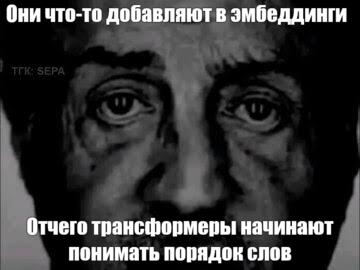

In [4]:
Image('IM_R.jpg', width=300, height=150 )

RoPE (Rotary Position Embedding) — это практическое применение ортогональных матриц в современных нейросетях (трансформерах). Чтобы языковая модель понимала порядок слов, в их векторные представления «встраивают» позицию. RoPE делает это с помощью умножения на матрицу поворота. Чем дальше разнесены слова в предложении, тем на больший угол разносятся их эмбеддинги. Это позволяет модели легко вычислять относительное расстояние между словами.

В каждом слое Attention происходит вращение соседних пар координат запросов $q_m$ и ключей $k_n$ на угол, пропорциональный их абсолютной позиции. В двумерном случае для пары компонент $(x_{2i}, x_{2i+1})$ на позиции m вращение задаётся матрицей $R_{\Theta,m}^{2}$ с углом $m\theta_i$, где $\theta_i = \text{base}^{-2i/d}$ — частота, убывающая с номером пары. В полной d-мерной модели $R_{\Theta,m}^{d}$ имеет блочно-диагональный вид: каждая $2\times 2$ пара вращается на свой угол $m\theta_i$, так что $\tilde{q}_m = R_{\Theta,m}^{d} q_m, \tilde{k}_n = R_{\Theta,n}^{d} k_n$. Важно, что вращение применяется только к Q и K, но не к V: позиция влияет на то, «кто на кого смотрит», а не на передаваемое содержимое.
 
Ключевое свойство RoPE — зависимость скалярного произведения только от относительного сдвига n-m. Благодаря ортогональности матриц вращения, скалярное произведение $R_{\Theta,m}^{\top} R_{\Theta,n} = R_{\Theta,n-m},$ превращается в функцию от n-m:

$\tilde{q}_m^\top \tilde{k}_n = q^\top R_{\Theta,m}^{\top} R_{\Theta,n} k = q^\top R_{\Theta,n-m} k .$

В работе GRAPE https://arxiv.org/pdf/2512.07805 2025 года было показано, что основной вклад дает именно идея использовать вращения, выбор конкретных пар координат, вокруг которых вращаем, не дает существенного прироста качества.

# 5.6. Классические нейронные сети. Ограничения линейных сетей.

Сколь бы ни была удобна линейная алгебра, у нее есть свои ограничения. Однако, с ее помощью особенно удобно записать и проанализировать классические, дотрансформенные нейронные сети. 

Для многослойной нейросети (MLP) с нелинейной активацией формулы такие:

- $a^{(0)} = x$,
 
- для каждого слоя $l=1,\dots,L$ результирующий вектор $a^{(l)}$ вычисляется по формулам:

$$z^{(l)} = W^{(l)} a^{(l-1)} + b^{(l)},
\qquad
a^{(l)} = \sigma^{(l)}\!\left(z^{(l)}\right),$$
 
где $\sigma^{(l)}$ — нелинейная функция активации, а $W$ - очередная матрица весов. 

- Выход сети: $y = W^{(L+1)} a^{(L)} + b^{(L+1)}.$
 
Именно нелинейность $\sigma$ не даёт всей композиции свернуться в одно эффективное линейное преобразование. Без нелинейности для двух слоёв имеем
$$h = W_1 x + b_1,\qquad y = W_2 h + b_2.$$
Подставляя:
$$y = W_2(W_1 x + b_1) + b_2
= (W_2 W_1)x + (W_2 b_1 + b_2)
= W_{\text{eff}} x + b_{\text{eff}}.$$
То же самое рекурсивно верно для любого числа слоёв.

#  post scriptum

Линейная алгебра является одним из базовых курсов в подготовке физиков и математиков. Она тесно связана с дифференциальным исчислением, которое приближённо описывает приращение функции в окрестности точки через линейную часть — дифференциал — и производную. 

Курсами, непосредственно продолжающими её, являются

- дифференциальной геометрии, где иизучаются локальные свойства многообразий (в частности, поверхностей) в многомерном пространстве — в рамках линейного приближения,

- функционального анализа, где происходит переход в бесконечномерные пространства, и, кроме того, обобщение алгебраических и геометрических понятий и конструкций линейной алгебры.